# Does Sooter's $d_2$ measure the distance to criticality of the branching network?

Systematic test of the proximity-to-criticality measure $d_b$ (Sooter et al. 2025, `src.analysis.prox_crit.calc_db`) on the all-to-all branching network (`src.models.branching_model`). This network is an ideal test bed, because we know the ground truth exactly.

**Ground truth.** The population activity is linear in its conditional mean, $E[A_{t+1} \mid A_t] = N\lambda + \sigma_\mathrm{eff} A_t$, and the noise $A_{t+1} - E[A_{t+1} \mid A_t]$ is a martingale difference, hence white. So the second-order statistics of $A_t$ are *exactly* those of an AR(1) process with $\phi = \sigma_\mathrm{eff} = 1 - \epsilon$, for any $N$ and firing rate. This gives two ground truths:
- $\epsilon = 1 - \sigma_\mathrm{eff}$, the distance in parameter space. The relaxation time is $\tau = -1/\ln(1-\epsilon) \approx 1/\epsilon$ steps.
- The **exact $d_b$** of the true kernel $[1-\epsilon, 0, \dots, 0]$, computed with `minimize_klr_b` without any data. For order 1 there is a closed form, $d_2 = -\tfrac12 \log_2(1 - \epsilon/2) \approx \epsilon / (4 \ln 2)$ (derived in `prox_crit_branching_network.ipynb`).

Any difference between the estimate and the exact $d_b$ is estimation error: finite data, the AR fit, the optimizer, or the numerical integration.

**Sweeps**, one direction at a time, with everything else at the defaults set below:
0. numerics: can `calc_db` compute the exact $d_2$ close to criticality at all?
1. distance $\epsilon$: does $\hat d_2$ track the ground truth?
2. window length $T$: how much data is needed?
3. AR order: what changes with AR(10)?
4. type of criticality $b = 2, 4, 6$
5. subsampling: observing only part of the network
6. network size $N$ and firing rate

Units: the network has no physical time step, so `delta_t = 1` and all $d_b$ are in **bits per time step**. Hats denote estimates from simulated data: $\hat d_b$.

In [1]:
%load_ext jupyter_black

import os
from concurrent.futures import ProcessPoolExecutor
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr

from src.analysis.prox_crit import calc_db, get_klr_b, minimize_klr_b
from src.analysis.prox_crit.distance import NATS_TO_BITS
from src.config.paths import FIGURES_DIR
from src.models.branching_model.branching_network import (
    params_for_distance,
    bn_aa_population,
)

## Settings

The scale parameters in the first block set the run time. The current values are for drafting (a few minutes on 8 cores). For the final run, raise `N_NEURONS`, `T_WINDOW` and `N_REPEATS`. The run time grows linearly with `T_WINDOW` and with `N_REPEATS`, and does not depend on `N_NEURONS`, because the simulation is population-level (binomial draws).

In [2]:
# --- scale (drafting values) ---
N_NEURONS = 1_000  # network size N
T_WINDOW = 100_000  # default measurement length, time steps
N_REPEATS = 10  # independent simulations per parameter point

# --- defaults of every sweep ---
RATE = 0.1  # stationary firing probability per neuron and step, a* = E[A]/N
ORDER = 5  # AR order, as in Sooter's demo
DISTANCES = np.logspace(-4, -0.5, 15)  # epsilon = 1 - sigma_eff
EXAMPLE_DISTANCES = (1e-3, 1e-2, 1e-1)  # tau ~ 1000, 100, 10 steps

# calc_db takes ~0.3 s at order 5 and ~1 s at order 10, so it runs in parallel worker processes. Only functions importable from src can be sent to the workers, not functions defined in this notebook.
POOL = ProcessPoolExecutor(max_workers=os.cpu_count())

# --- plotting ---
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.size": 10,
        "axes.titlesize": 10.5,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#d9d8d4",
        "grid.linewidth": 0.6,
        "legend.frameon": False,
        "lines.linewidth": 2,
    }
)
TRUTH_COLOR = "#3d3d3a"  # exact ground truth and theory, neutral ink
FLOOR_COLOR = "#b5b4ae"  # shading of the numerically unresolved region (section 0)
DISTANCE_COLORS = {1e-3: "#2a78d6", 1e-2: "#eb6834", 1e-1: "#1baf7a"}
BETA_COLORS = {2: "#2a78d6", 4: "#eb6834", 6: "#1baf7a"}
RATE_COLORS = {0.01: "#2a78d6", 0.1: "#eb6834", 0.5: "#1baf7a"}
ORDER_COLORS = {
    1: "#86b6ef",
    2: "#3987e5",
    5: "#1c5cab",
    10: "#0d366b",
}  # one-hue ramp: order is ordinal

print(f"{os.cpu_count()} worker processes")
print(
    f"default network: N = {N_NEURONS}, rate = {RATE}, window T = {T_WINDOW} steps, {N_REPEATS} repeats per point"
)
print(
    f"distance grid: {len(DISTANCES)} values of epsilon in [{DISTANCES[0]:.1e}, {DISTANCES[-1]:.2f}]"
)
print(
    f"T / tau at the default window: {T_WINDOW * DISTANCES[0]:.0f} (closest to criticality) to {T_WINDOW * DISTANCES[-1]:.0f}"
)

8 worker processes
default network: N = 1000, rate = 0.1, window T = 100000 steps, 10 repeats per point
distance grid: 15 values of epsilon in [1.0e-04, 0.32]
T / tau at the default window: 10 (closest to criticality) to 31623


Helpers, used in all sweeps. `estimate_db` always uses the maximum-likelihood fit, as in Sooter's demo; it is also the only fit that gives error bars.

In [3]:
def simulate(distance, T=T_WINDOW, R=N_REPEATS, N=N_NEURONS, rate=RATE, seed=0):
    # Activity of R independent networks at distance epsilon, started in the stationary state: ndarray (R, T) of int.
    sigma, h = params_for_distance(rate=rate, distance=distance)
    return bn_aa_population(N=N, sigma=sigma, T=T, h=h, R=R, seed=seed)


def estimate_db(traces, order=ORDER, b=2, with_err_bars=False):
    # d_b in bits/step of each trace (computed in parallel): ndarray (len(traces),), and with error bars also sddb. Failed estimates (exit status 1, e.g. an explosive fit) are nan.
    fit = partial(
        calc_db,
        order=order,
        delta_t=1.0,
        b=b,
        fit_method="MaxLikelihood",
        with_err_bars=with_err_bars,
    )
    results = list(POOL.map(fit, traces))
    failed = np.array([result.exit_status != 0 for result in results])
    db = np.where(failed, np.nan, [result.db for result in results])
    if not with_err_bars:
        return db
    # known issue (NOTICE.md): sddb is complex when the Hessian is not negative definite; such error bars are unusable -> nan
    sddb = [
        float(result.sddb) if np.isreal(result.sddb) else np.nan for result in results
    ]
    return db, np.where(failed, np.nan, sddb)


def true_db(distances, order=ORDER, b=2):
    # Exact d_b in bits/step of the true kernel [1 - epsilon, 0, ..., 0] embedded in AR(order), no data involved: ndarray (len(distances),)
    kernels = [np.r_[1 - distance, np.zeros(order - 1)] for distance in distances]
    results = POOL.map(partial(minimize_klr_b, b=b), kernels)
    return np.array([db for db, _, _ in results]) * NATS_TO_BITS


def plot_median_iqr(ax, x, values, color, label=None, **kwargs):
    # Median (line with markers) and interquartile band over the repeats, the last axis of values.
    q25, median, q75 = np.nanpercentile(values, [25, 50, 75], axis=-1)
    ax.fill_between(x, q25, q75, color=color, alpha=0.18, linewidth=0)
    ax.plot(
        x,
        median,
        color=color,
        marker="o",
        markersize=5,
        markeredgecolor="white",
        markeredgewidth=0.8,
        label=label,
        **kwargs,
    )


def shade_numerical_floor(ax, label="numerical floor"):
    # Grey band over epsilon <= EPS_FLOOR, where calc_db cannot resolve d_2 (section 0). Keeps the current x-limits.
    xlim = ax.get_xlim()
    ax.axvspan(
        xlim[0],
        EPS_FLOOR,
        color=FLOOR_COLOR,
        alpha=0.25,
        linewidth=0,
        label=label,
        zorder=0,
    )
    ax.set_xlim(xlim)

## The network activity

Three distances from criticality. Left: activity (fraction of active neurons per step). Right: autocorrelation of the full traces against the AR(1) ground truth $(1-\epsilon)^k$.

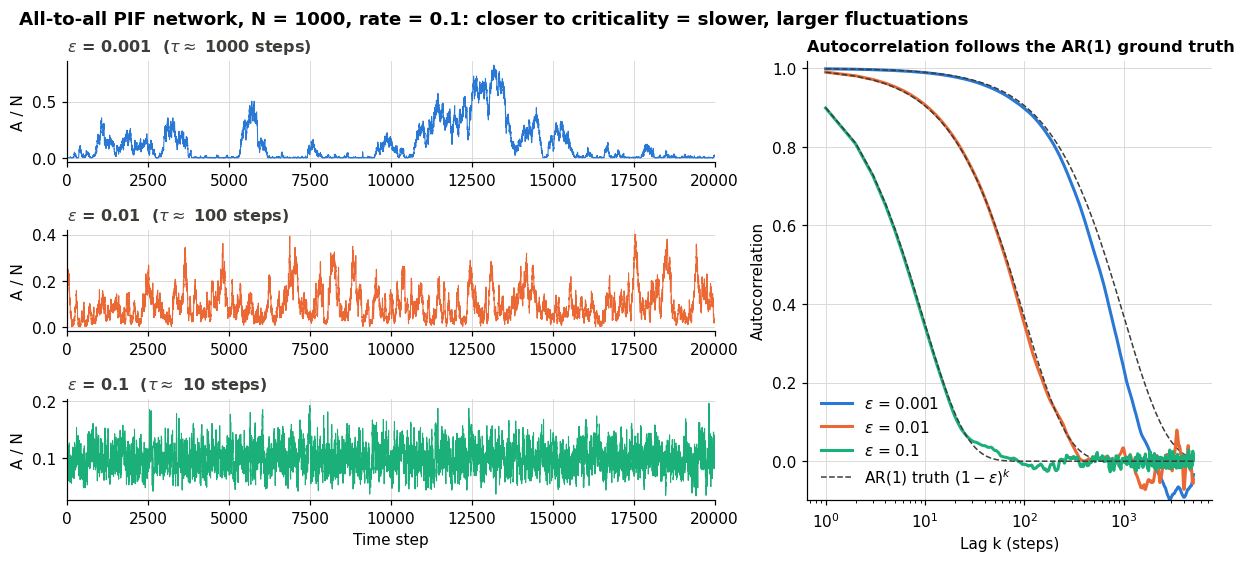

epsilon = 0.001: A in [0, 858], mean 88.3 (theory 100), std 156.7, T / tau = 100
epsilon = 0.01: A in [0, 450], mean 103.3 (theory 100), std 68.2, T / tau = 1000
epsilon = 0.1: A in [33, 209], mean 100.1 (theory 100), std 21.6, T / tau = 10000


In [4]:
# example_activity = {epsilon: ndarray (T,) of int}
example_activity = {
    distance: simulate(distance, R=1, seed=(0, i))[0]
    for i, distance in enumerate(EXAMPLE_DISTANCES)
}

max_lag = 5_000
lags = np.arange(max_lag + 1)
fig, axes = plt.subplot_mosaic(
    [[d, "acf"] for d in EXAMPLE_DISTANCES],
    figsize=(11, 5),
    width_ratios=[1.6, 1],
    layout="constrained",
)
for distance, activity in example_activity.items():
    color = DISTANCE_COLORS[distance]
    ax = axes[distance]
    ax.plot(activity[:20_000] / N_NEURONS, color=color, linewidth=0.7)
    ax.set_ylabel("A / N")
    ax.set_title(
        rf"$\epsilon$ = {distance:g}  ($\tau \approx$ {1 / distance:.0f} steps)",
        color=TRUTH_COLOR,
    )
    ax.set_xlim(0, 20_000)

    # autocorrelation via FFT, zero-padded to avoid circular wrap-around
    centered = activity - activity.mean()
    autocovariance = np.fft.irfft(
        np.abs(np.fft.rfft(centered, n=2 * len(centered))) ** 2
    )[: max_lag + 1]
    axes["acf"].plot(
        lags[1:],
        autocovariance[1:] / autocovariance[0],
        color=color,
        label=rf"$\epsilon$ = {distance:g}",
    )
    axes["acf"].plot(
        lags[1:],
        (1 - distance) ** lags[1:],
        color=TRUTH_COLOR,
        linestyle="--",
        linewidth=1,
    )
axes[EXAMPLE_DISTANCES[-1]].set_xlabel("Time step")
axes["acf"].plot(
    [],
    [],
    color=TRUTH_COLOR,
    linestyle="--",
    linewidth=1,
    label=r"AR(1) truth $(1-\epsilon)^k$",
)
axes["acf"].set(
    xscale="log",
    xlabel="Lag k (steps)",
    ylabel="Autocorrelation",
    ylim=(-0.1, 1.02),
    title="Autocorrelation follows the AR(1) ground truth",
)
axes["acf"].legend(loc="lower left")
fig.suptitle(
    f"All-to-all BN, N = {N_NEURONS}, rate = {RATE}: closer to criticality = slower, larger fluctuations",
    fontweight="bold",
    x=0.01,
    ha="left",
)
plt.show()
# fig.savefig(FIGURES_DIR / "sooter_x_bn_activity.png", dpi=200, bbox_inches="tight")

for distance, activity in example_activity.items():
    print(
        f"epsilon = {distance:g}: A in [{activity.min()}, {activity.max()}], mean {activity.mean():.1f} (theory {RATE * N_NEURONS:.0f}), std {activity.std():.1f}, T / tau = {T_WINDOW * distance:.0f}"
    )

## 0. Numerics: can `calc_db` resolve $d_2$ close to criticality?

Before looking at data: is the exact $d_2$ of the true kernel computed correctly? No data are involved here, only the two numerical steps of `calc_db`:
- **quadrature**: for order 1, $M_2$ is a single point (the random walk), so $d_2$ is one KL-rate integral, with no optimizer. Compare it to the closed form.
- **quadrature + optimizer**: for order 5, `minimize_klr_b` minimizes that integral over $M_2$. Close to criticality it should agree with order 1 to within ~1% (section 3).

The integrand has a peak of width $\sim\epsilon$ at $\omega = 0$, because the fitted spectrum is $\propto 1/|1 - \phi e^{-i\omega}|^2$ with $|1 - \phi| = \epsilon$.

C:\Users\andre\OneDrive\Education\4_Tuebingen\Comp_Neuroscience\3_4_Lab_rotations\1_Anna_Levina_critical_networks\repository\src\analysis\prox_crit\kl_rate.py:129: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  klr, _ = quad(integrand, -np.pi, np.pi, points=[0.0], **QUAD_OPTS)
C:\Users\andre\OneDrive\Education\4_Tuebingen\Comp_Neuroscience\3_4_Lab_rotations\1_Anna_Levina_critical_networks\repository\src\analysis\prox_crit\kl_rate.py:129: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  klr, _ = quad(integrand, -np.pi, np.pi, points=[0.0], **QUAD_OPTS)


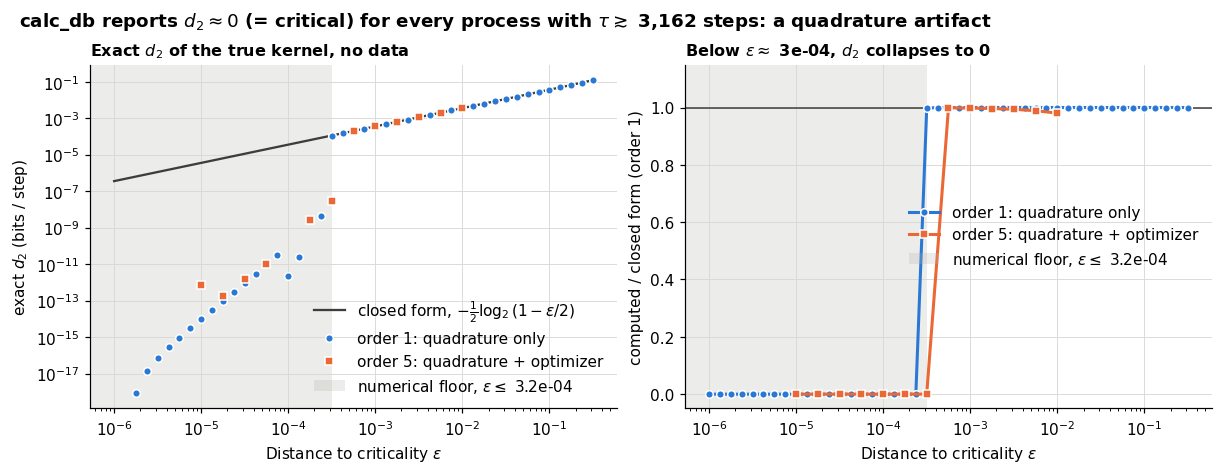

epsilon     closed form   order-1 quadrature   ratio
 1.0e-06    3.607e-07     -1.840e-17       -0.000
 3.2e-06    1.141e-06      7.606e-17        0.000
 1.0e-05    3.607e-06      9.718e-15        0.000
 3.2e-05    1.141e-05      9.690e-13        0.000
 1.0e-04    3.607e-05      2.410e-12        0.000
 3.2e-04    1.141e-04      1.138e-04        0.997
 1.0e-03    3.608e-04      3.608e-04        1.000
 3.2e-03    1.141e-03      1.141e-03        1.000
 1.0e-02    3.616e-03      3.616e-03        1.000
 3.2e-02    1.150e-02      1.150e-02        1.000
 1.0e-01    3.700e-02      3.700e-02        1.000
 3.2e-01    1.242e-01      1.242e-01        1.000

order 5 (optimizer) / closed form: [ 0.     0.     0.     0.    -0.     0.     0.     0.999  0.998  0.996
  0.994  0.989  0.98 ] at epsilon [1.000e-05 1.800e-05 3.200e-05 5.600e-05 1.000e-04 1.780e-04 3.160e-04
 5.620e-04 1.000e-03 1.778e-03 3.162e-03 5.623e-03 1.000e-02]
EPS_FLOOR = 3.16e-04  (relaxation time ~ 3162 steps)


In [5]:
check_distances = np.logspace(-6, -0.5, 45)
closed_form_check = -0.5 * np.log2(1 - check_distances / 2)
# order 1: get_klr_b with an empty reduced kernel = KL rate to the random walk, as minimize_klr_b does for order b/2
quadrature_order_1 = (
    np.array(
        [get_klr_b([1 - distance], [], 2, "integral") for distance in check_distances]
    )
    * NATS_TO_BITS
)
floor_distances = np.logspace(-5, -2, 13)
optimizer_order_5 = true_db(floor_distances)
order_5_relative = optimizer_order_5 / (-0.5 * np.log2(1 - floor_distances / 2))

# numerical floor: largest epsilon at which the order-5 exact d_2 is off by more than 5%
EPS_FLOOR = floor_distances[np.abs(order_5_relative - 1) > 0.05].max()

fig, (ax_value, ax_ratio) = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
ax_value.plot(
    check_distances,
    closed_form_check,
    color=TRUTH_COLOR,
    linewidth=1.5,
    label=r"closed form, $-\frac{1}{2}\log_2(1 - \epsilon/2)$",
)
ax_value.plot(
    check_distances,
    quadrature_order_1,
    color=BETA_COLORS[2],
    linestyle="none",
    marker="o",
    markersize=5,
    markeredgecolor="white",
    label="order 1: quadrature only",
)
ax_value.plot(
    floor_distances,
    optimizer_order_5,
    color=BETA_COLORS[4],
    linestyle="none",
    marker="s",
    markersize=5,
    markeredgecolor="white",
    label=f"order {ORDER}: quadrature + optimizer",
)
ax_value.set(
    xscale="log",
    yscale="log",
    xlabel=r"Distance to criticality $\epsilon$",
    ylabel=r"exact $d_2$ (bits / step)",
    title=r"Exact $d_2$ of the true kernel, no data",
)
ax_ratio.axhline(1, color=TRUTH_COLOR, linewidth=1)
ax_ratio.plot(
    check_distances,
    quadrature_order_1 / closed_form_check,
    color=BETA_COLORS[2],
    marker="o",
    markersize=5,
    markeredgecolor="white",
    label="order 1: quadrature only",
)
ax_ratio.plot(
    floor_distances,
    order_5_relative,
    color=BETA_COLORS[4],
    marker="s",
    markersize=5,
    markeredgecolor="white",
    label=f"order {ORDER}: quadrature + optimizer",
)
ax_ratio.set(
    xscale="log",
    xlabel=r"Distance to criticality $\epsilon$",
    ylabel="computed / closed form (order 1)",
    ylim=(-0.05, 1.15),
    title=r"Below $\epsilon \approx$" + f" {EPS_FLOOR:.0e}, " + r"$d_2$ collapses to 0",
)
for ax in (ax_value, ax_ratio):
    shade_numerical_floor(
        ax, label=rf"numerical floor, $\epsilon \leq$ {EPS_FLOOR:.1e}"
    )
ax_value.legend(loc="lower right")
ax_ratio.legend(loc="center right")
fig.suptitle(
    rf"calc_db reports $d_2 \approx 0$ (= critical) for every process with $\tau \gtrsim$ {1 / EPS_FLOOR:,.0f} steps: a quadrature artifact",
    fontweight="bold",
    x=0.01,
    ha="left",
)
plt.show()
# fig.savefig(FIGURES_DIR / "sooter_x_bn_numerical_floor.png", dpi=200, bbox_inches="tight")

print("epsilon     closed form   order-1 quadrature   ratio")
for distance, exact, computed in zip(
    check_distances[::4], closed_form_check[::4], quadrature_order_1[::4]
):
    print(
        f"{distance:8.1e}   {exact:10.3e}   {computed:12.3e}      {computed / exact:7.3f}"
    )
print(
    f"\norder {ORDER} (optimizer) / closed form: {np.round(order_5_relative, 3)} at epsilon {np.round(floor_distances, 6)}"
)
print(f"EPS_FLOOR = {EPS_FLOOR:.2e}  (relaxation time ~ {1 / EPS_FLOOR:.0f} steps)")
# The quadrature (scipy quad, epsabs = 1e-10, as MATLAB's integral() in the original) does not resolve the peak of width ~epsilon at omega = 0: for order 1 the integral drops to ~0 below epsilon ~ 1e-4.
# At order 5 it fails earlier: the optimizer actively searches for a critical kernel whose integrand the quadrature misses, and finds one at d_2 ~ 0.
# A log-spaced trapezoid grid near omega = 0 recovers the closed form at the very same kernels (checked while drafting), so this is integration error, not a property of d_2.

**Take-home.** `calc_db` cannot resolve $d_2$ for processes with a relaxation time above a few thousand time steps: the adaptive quadrature misses the narrow low-frequency peak, and the optimizer exploits that. Such a process is reported as $d_2 \approx 0$, i.e. as *exactly critical*. The floor is $\epsilon \approx 3 \cdot 10^{-4}$, i.e. $\tau \approx 3000$ bins; for Sooter's 40 ms bins that is $\tau \approx 2$ minutes, so it is irrelevant for the cortical data but relevant for any model simulated close to criticality. The grey band marks this region in all following $\epsilon$-plots; estimates whose *fitted* kernel falls into it collapse in the same way. Likely the same in the MATLAB original (same integration tolerances), not verified. A fix would be to split the integral at $\pm c\,\epsilon$ (several multiples of the peak width) or to integrate on a log-spaced grid near $\omega = 0$.

## Main simulation: sweep over the distance $\epsilon$

One set of networks per $\epsilon$ (`N_REPEATS` independent repeats each). All estimates that need this sweep are computed here in one pass, so the traces never have to be stored: $\hat d_2$ for AR orders 1, 2, 5 and 10 (section 3), and $\hat d_4$, $\hat d_6$ at order 5 (section 4).

In [6]:
ORDERS = (1, 2, 5, 10)
BETAS = (2, 4, 6)
# estimate_settings = list of (order, b); estimates[(order, b)] = ndarray (len(DISTANCES), N_REPEATS) of d_b in bits/step
estimate_settings = [(order, 2) for order in ORDERS] + [
    (ORDER, b) for b in BETAS if b != 2
]
estimates = {
    setting: np.empty((len(DISTANCES), N_REPEATS)) for setting in estimate_settings
}
for i, distance in enumerate(DISTANCES):
    activity = simulate(distance, seed=(1, i))
    for order, b in estimate_settings:
        estimates[(order, b)][i] = estimate_db(activity, order=order, b=b)

# exact d_b on the same grid, and the order-1 closed form on a dense grid for smooth curves
truths = {
    (order, b): true_db(DISTANCES, order=order, b=b) for order, b in estimate_settings
}
dense_distances = np.logspace(np.log10(DISTANCES[0]), np.log10(DISTANCES[-1]), 200)
closed_form_d2 = -0.5 * np.log2(1 - dense_distances / 2)  # exact d_2 for order 1

for (order, b), db in estimates.items():
    print(
        f"order {order:2d}, b = {b}: shape {db.shape}, d_b in [{np.nanmin(db):.2e}, {np.nanmax(db):.2e}] bits/step, failed fits: {np.isnan(db).sum()}"
    )

order  1, b = 2: shape (15, 10), d_b in [-5.22e-13, 1.25e-01] bits/step, failed fits: 0
order  2, b = 2: shape (15, 10), d_b in [9.65e-12, 1.07e-01] bits/step, failed fits: 0
order  5, b = 2: shape (15, 10), d_b in [-8.82e-12, 7.43e-02] bits/step, failed fits: 0
order 10, b = 2: shape (15, 10), d_b in [-3.00e-11, 4.93e-02] bits/step, failed fits: 0
order  5, b = 4: shape (15, 10), d_b in [1.53e-01, 3.39e-01] bits/step, failed fits: 0
order  5, b = 6: shape (15, 10), d_b in [6.36e-01, 2.49e+00] bits/step, failed fits: 1


## 1. Does $\hat d_2$ track the true distance?

Default setting: AR order 5, $b = 2$, window $T$ = `T_WINDOW`. Left: estimates against $\epsilon$ (dots: single networks). Right: the same estimates relative to the exact $d_2$; the dashed band is the order-1 theory for the relative standard deviation, $\sqrt{2/(\epsilon T)}$ (derived in section 2).

C:\Users\andre\miniconda3\envs\Levina_rotation_1\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1620: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


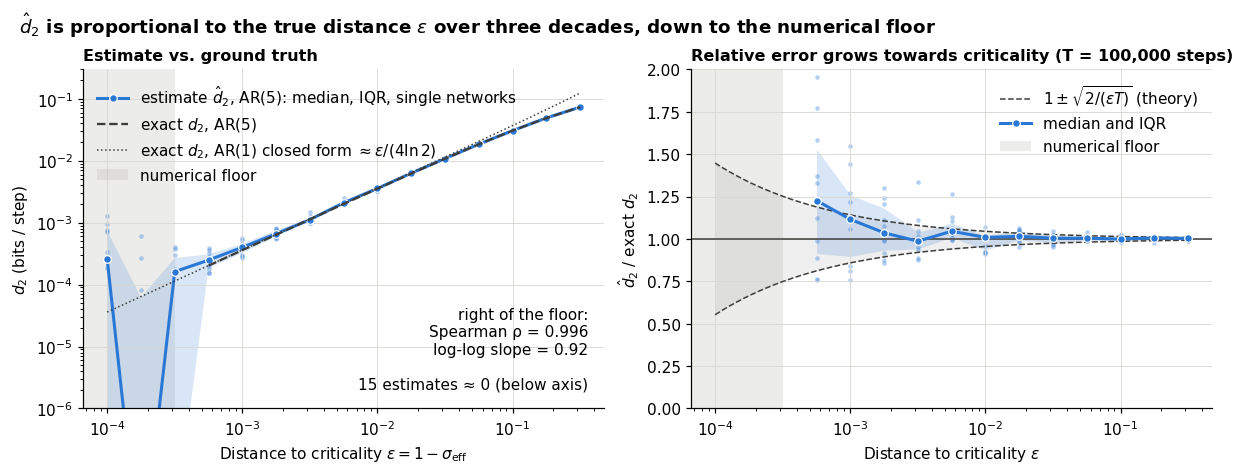

Spearman correlation of d_2 estimate with epsilon: rho = 0.9957 above the floor (120 estimates), 0.9663 including the floor region
log-log slope of median d_2 vs epsilon above the floor: 0.925 (1 = proportional)
estimates collapsed below 1e-06 bits/step: 15, at epsilon [0.0001     0.00017783 0.00031623]
epsilon    T/tau   exact d_2    median ratio   IQR of ratio   (nan: inside the floor)
 1.0e-04       10   -7.62e-12        nan      [nan, nan]
 1.8e-04       18    2.64e-09        nan      [nan, nan]
 3.2e-04       32    3.05e-08        nan      [nan, nan]
 5.6e-04       56    2.03e-04      1.226      [0.91, 1.53]
 1.0e-03      100    3.60e-04      1.116      [0.90, 1.26]
 1.8e-03      178    6.39e-04      1.036      [0.93, 1.18]
 3.2e-03      316    1.13e-03      0.986      [0.94, 1.04]
 5.6e-03      562    2.01e-03      1.045      [1.01, 1.09]
 1.0e-02     1000    3.54e-03      1.009      [0.93, 1.02]
 1.8e-02     1778    6.22e-03      1.015      [0.99, 1.05]
 3.2e-02     3162    1.08

C:\Users\andre\miniconda3\envs\Levina_rotation_1\lib\site-packages\numpy\lib\_nanfunctions_impl.py:1409: RuntimeWarning: All-NaN slice encountered
  return _nanquantile_unchecked(


In [7]:
db_default = estimates[(ORDER, 2)]
db_true_default = truths[(ORDER, 2)]
above_floor = DISTANCES > EPS_FLOOR  # where the exact d_2 is computable (section 0)
distances_repeated = np.repeat(
    DISTANCES[:, None], N_REPEATS, axis=1
)  # ndarray (len(DISTANCES), N_REPEATS), matches db_default
rho_all, _ = spearmanr(
    distances_repeated.ravel(), db_default.ravel(), nan_policy="omit"
)
rho, _ = spearmanr(
    distances_repeated[above_floor].ravel(),
    db_default[above_floor].ravel(),
    nan_policy="omit",
)
log_slope = np.polyfit(
    np.log10(DISTANCES[above_floor]),
    np.log10(np.nanmedian(db_default[above_floor], axis=1)),
    deg=1,
)[0]
value_floor = (
    1e-6  # lower y-limit; estimates below it are collapsed to ~0 by the numerical floor
)
n_collapsed = np.sum(db_default < value_floor)

fig, (ax_value, ax_ratio) = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
ax_value.scatter(
    distances_repeated.ravel(),
    db_default.ravel(),
    s=9,
    color=BETA_COLORS[2],
    alpha=0.35,
    linewidth=0,
)
plot_median_iqr(
    ax_value,
    DISTANCES,
    db_default,
    BETA_COLORS[2],
    label=rf"estimate $\hat d_2$, AR({ORDER}): median, IQR, single networks",
)
ax_value.plot(
    DISTANCES[above_floor],
    db_true_default[above_floor],
    color=TRUTH_COLOR,
    linestyle="--",
    linewidth=1.5,
    label=rf"exact $d_2$, AR({ORDER})",
)
ax_value.plot(
    dense_distances,
    closed_form_d2,
    color=TRUTH_COLOR,
    linestyle=":",
    linewidth=1,
    label=r"exact $d_2$, AR(1) closed form $\approx \epsilon / (4 \ln 2)$",
)
ax_value.set(
    xscale="log",
    yscale="log",
    ylim=(value_floor, 0.3),
    xlabel=r"Distance to criticality $\epsilon = 1 - \sigma_\mathrm{eff}$",
    ylabel=r"$d_2$ (bits / step)",
    title="Estimate vs. ground truth",
)
shade_numerical_floor(ax_value)
ax_value.text(
    0.97,
    0.05,
    f"right of the floor:\nSpearman ρ = {rho:.3f}\nlog-log slope = {log_slope:.2f}\n\n{n_collapsed} estimates ≈ 0 (below axis)",
    transform=ax_value.transAxes,
    ha="right",
    va="bottom",
)
ax_value.legend(loc="upper left")

# ratio only where the exact d_2 is computable
ratio = np.where(above_floor[:, None], db_default / db_true_default[:, None], np.nan)
relative_std_theory = np.sqrt(2 / (dense_distances * T_WINDOW))
ax_ratio.fill_between(
    dense_distances,
    1 - relative_std_theory,
    1 + relative_std_theory,
    color=TRUTH_COLOR,
    alpha=0.08,
    linewidth=0,
)
ax_ratio.plot(
    dense_distances,
    1 + relative_std_theory,
    color=TRUTH_COLOR,
    linestyle="--",
    linewidth=1,
)
ax_ratio.plot(
    dense_distances,
    1 - relative_std_theory,
    color=TRUTH_COLOR,
    linestyle="--",
    linewidth=1,
    label=r"$1 \pm \sqrt{2/(\epsilon T)}$ (theory)",
)
ax_ratio.axhline(1, color=TRUTH_COLOR, linewidth=1)
ax_ratio.scatter(
    distances_repeated.ravel(),
    ratio.ravel(),
    s=9,
    color=BETA_COLORS[2],
    alpha=0.35,
    linewidth=0,
)
plot_median_iqr(ax_ratio, DISTANCES, ratio, BETA_COLORS[2], label="median and IQR")
ax_ratio.set(
    xscale="log",
    xlabel=r"Distance to criticality $\epsilon$",
    ylabel=r"$\hat d_2$ / exact $d_2$",
    ylim=(0, 2),
    title=f"Relative error grows towards criticality (T = {T_WINDOW:,} steps)",
)
shade_numerical_floor(ax_ratio)
ax_ratio.legend(loc="upper right")
fig.suptitle(
    r"$\hat d_2$ is proportional to the true distance $\epsilon$ over three decades, down to the numerical floor",
    fontweight="bold",
    x=0.01,
    ha="left",
)
plt.show()
# fig.savefig(FIGURES_DIR / "sooter_x_bn_distance_sweep.png", dpi=200, bbox_inches="tight")

print(
    f"Spearman correlation of d_2 estimate with epsilon: rho = {rho:.4f} above the floor ({np.isfinite(db_default[above_floor]).sum()} estimates), {rho_all:.4f} including the floor region"
)
print(
    f"log-log slope of median d_2 vs epsilon above the floor: {log_slope:.3f} (1 = proportional)"
)
print(
    f"estimates collapsed below {value_floor:g} bits/step: {n_collapsed}, at epsilon {DISTANCES[np.any(db_default < value_floor, axis=1)]}"
)
print(
    "epsilon    T/tau   exact d_2    median ratio   IQR of ratio   (nan: inside the floor)"
)
for distance, exact, ratios in zip(DISTANCES, db_true_default, ratio):
    q25, q50, q75 = np.nanpercentile(ratios, [25, 50, 75])
    print(
        f"{distance:8.1e} {T_WINDOW * distance:8.0f}   {exact:9.2e}   {q50:8.3f}      [{q25:.2f}, {q75:.2f}]"
    )

**Take-home.** Outside the numerical floor, $\hat d_2$ is a faithful, monotonic readout of the distance to criticality: its rank correlation with $\epsilon$ is close to 1 (0.996 in the drafting run), and it is proportional to $\epsilon$ for small $\epsilon$. The overall log-log slope is slightly below 1 (0.92), because far from criticality the AR(5) value bends below the AR(1) closed form (dotted; see section 3). Close to criticality $d_2 \approx \epsilon / (4 \ln 2) \approx 1 / (4 \ln 2 \cdot \tau)$ bits/step, so for this network **$d_2$ is essentially the inverse relaxation time**. The relative error follows $\sqrt{2/(\epsilon T)}$: at a fixed window length, the measure becomes *less* precise the closer the system is to criticality (section 2). Inside the floor the estimate collapses to ~0, so there it says "critical" for any $\epsilon$.

## 2. How long must the measurement be?

For three distances, the estimate is computed on growing windows (the first $T$ steps of the same traces), with error bars.

**Theory (AR(1) fit).** The least-squares estimate of $\phi$ has variance $(1 - \phi^2)/T \approx 2\epsilon / T$. Since $d_2 \propto \epsilon$ close to criticality, the relative error is
$$\frac{\mathrm{sd}(\hat d_2)}{d_2} \approx \frac{\mathrm{sd}(\hat\epsilon)}{\epsilon} = \sqrt{\frac{2}{\epsilon T}} \approx \sqrt{\frac{2\tau}{T}}.$$
So the accuracy should depend only on $T / \tau$, the window length in units of the relaxation time. The same holds for higher AR orders near criticality, because there $d_2$ depends mostly on the kernel sum $\sum_k \phi_k$, whose variance $\mathbf{1}^\top \Gamma^{-1} \mathbf{1} / T = (2\epsilon + (n-2)\epsilon^2)/T$ is the same as for order 1 to leading order in $\epsilon$.

In [8]:
WINDOWS = np.unique(np.logspace(2, np.log10(T_WINDOW), 10).astype(int))
# window_db[epsilon], window_sddb[epsilon] = ndarray (len(WINDOWS), N_REPEATS); window_truth[epsilon] = exact d_2 (float)
window_db, window_sddb = {}, {}
window_truth = dict(zip(EXAMPLE_DISTANCES, true_db(EXAMPLE_DISTANCES)))
for i, distance in enumerate(EXAMPLE_DISTANCES):
    activity = simulate(distance, seed=(2, i))
    results = [
        estimate_db(activity[:, :window], with_err_bars=True) for window in WINDOWS
    ]
    window_db[distance] = np.array([db for db, _ in results])
    window_sddb[distance] = np.array([sddb for _, sddb in results])

print(f"windows T: {WINDOWS}")
for distance in EXAMPLE_DISTANCES:
    db = window_db[distance]
    print(
        f"epsilon = {distance:g}: exact d_2 = {window_truth[distance]:.3e}, estimates shape {db.shape}, failed fits {np.isnan(db).sum()}, unusable error bars {np.isnan(window_sddb[distance]).sum()}"
    )

windows T: [   100    215    464   1000   2154   4641  10000  21544  46415 100000]
epsilon = 0.001: exact d_2 = 3.600e-04, estimates shape (10, 10), failed fits 0, unusable error bars 0
epsilon = 0.01: exact d_2 = 3.545e-03, estimates shape (10, 10), failed fits 0, unusable error bars 0
epsilon = 0.1: exact d_2 = 3.070e-02, estimates shape (10, 10), failed fits 0, unusable error bars 0


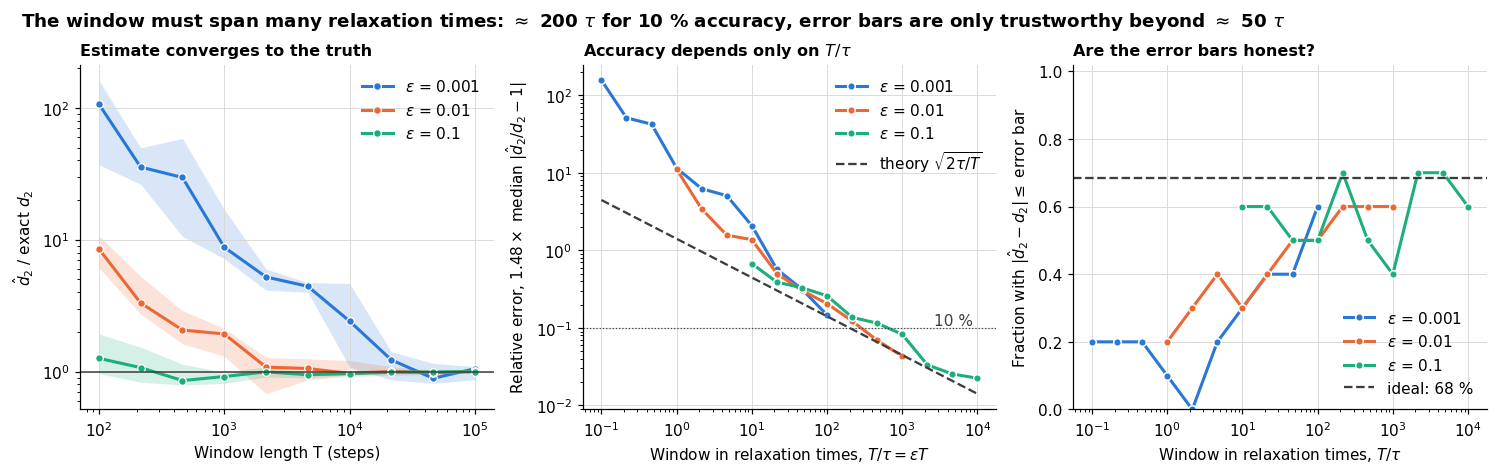

epsilon   T/tau   median ratio   robust rel. error   RMS rel. error   theory sqrt(2/(eps T))   median sddb / d_2
  0.001     0.1      107.13        157.352          138.034             4.472                51.575
  0.001     0.2       35.68         51.422           59.323             3.050                19.797
  0.001     0.5       29.71         42.572           44.017             2.076                11.734
  0.001     1.0        8.78         11.531           13.059             1.414                 5.019
  0.001     2.2        5.22          6.259            5.009             0.964                 2.276
  0.001     4.6        4.43          5.091            3.573             0.656                 1.392
  0.001    10.0        2.41          2.093            3.303             0.447                 0.749
  0.001    21.5        1.22          0.571            1.220             0.305                 0.356
  0.001    46.4        0.89          0.316            1.035             0.208          

In [9]:
fig, (ax_ratio, ax_collapse, ax_coverage) = plt.subplots(
    1, 3, figsize=(13.5, 4.2), layout="constrained"
)
for distance in EXAMPLE_DISTANCES:
    color = DISTANCE_COLORS[distance]
    tau = 1 / distance
    relative_error = window_db[distance] / window_truth[distance] - 1
    plot_median_iqr(
        ax_ratio,
        WINDOWS,
        relative_error + 1,
        color,
        label=rf"$\epsilon$ = {distance:g}",
    )

    # robust relative error (equals the std for unbiased Gaussian errors, insensitive to the rare outlier fits) and error-bar coverage, both over the repeats
    robust_error = 1.4826 * np.nanmedian(np.abs(relative_error), axis=1)
    ax_collapse.plot(
        WINDOWS / tau,
        robust_error,
        color=color,
        marker="o",
        markersize=5,
        markeredgecolor="white",
        label=rf"$\epsilon$ = {distance:g}",
    )
    absolute_error = np.abs(window_db[distance] - window_truth[distance])
    has_err_bar = np.isfinite(window_sddb[distance])
    coverage = np.sum(
        (absolute_error <= window_sddb[distance]) & has_err_bar, axis=1
    ) / np.maximum(has_err_bar.sum(axis=1), 1)
    ax_coverage.plot(
        WINDOWS / tau,
        coverage,
        color=color,
        marker="o",
        markersize=5,
        markeredgecolor="white",
        label=rf"$\epsilon$ = {distance:g}",
    )

ax_ratio.axhline(1, color=TRUTH_COLOR, linewidth=1)
ax_ratio.set(
    xscale="log",
    yscale="log",
    xlabel="Window length T (steps)",
    ylabel=r"$\hat d_2$ / exact $d_2$",
    title="Estimate converges to the truth",
)
ax_ratio.legend(loc="upper right")

windows_per_tau = np.logspace(-1, np.log10(WINDOWS[-1] * max(EXAMPLE_DISTANCES)), 100)
ax_collapse.plot(
    windows_per_tau,
    np.sqrt(2 / windows_per_tau),
    color=TRUTH_COLOR,
    linestyle="--",
    linewidth=1.5,
    label=r"theory $\sqrt{2\tau / T}$",
)
ax_collapse.axhline(0.1, color=TRUTH_COLOR, linewidth=0.8, linestyle=":")
ax_collapse.text(
    windows_per_tau[-1], 0.1, "10 % ", va="bottom", ha="right", color=TRUTH_COLOR
)
ax_collapse.set(
    xscale="log",
    yscale="log",
    xlabel=r"Window in relaxation times, $T / \tau = \epsilon T$",
    ylabel=r"Relative error, $1.48 \times$ median $|\hat d_2 / d_2 - 1|$",
    title=r"Accuracy depends only on $T / \tau$",
)
ax_collapse.legend(loc="upper right")

ax_coverage.axhline(
    0.683, color=TRUTH_COLOR, linestyle="--", linewidth=1.5, label="ideal: 68 %"
)
ax_coverage.set(
    xscale="log",
    xlabel=r"Window in relaxation times, $T / \tau$",
    ylabel=r"Fraction with $|\hat d_2 - d_2| \leq$ error bar",
    ylim=(0, 1.02),
    title="Are the error bars honest?",
)
ax_coverage.legend(loc="lower right")
fig.suptitle(
    r"The window must span many relaxation times: $\approx$ 200 $\tau$ for 10 % accuracy, error bars are only trustworthy beyond $\approx$ 50 $\tau$",
    fontweight="bold",
    x=0.01,
    ha="left",
)
plt.show()
# fig.savefig(FIGURES_DIR / "sooter_x_bn_window_length.png", dpi=200, bbox_inches="tight")

print(
    "epsilon   T/tau   median ratio   robust rel. error   RMS rel. error   theory sqrt(2/(eps T))   median sddb / d_2"
)
for distance in EXAMPLE_DISTANCES:
    relative_error = window_db[distance] / window_truth[distance] - 1
    for window, errors, sddb in zip(WINDOWS, relative_error, window_sddb[distance]):
        print(
            f"{distance:7g} {window * distance:7.1f}   {np.nanmedian(errors) + 1:9.2f}     {1.4826 * np.nanmedian(np.abs(errors)):10.3f}       {np.sqrt(np.nanmean(errors**2)):10.3f}        {np.sqrt(2 / (distance * window)):10.3f}              {np.nanmedian(sddb) / window_truth[distance]:8.3f}"
        )

**Take-home.** The accuracy of $\hat d_2$ is governed by a single number, the window length in relaxation times $T/\tau$: all three distances collapse onto the theory $\sqrt{2\tau/T}$. A 10% error needs $T \approx 200\,\tau$, so the closer to criticality, the longer the recording must be (for $\tau$ = 1000 steps: $2 \cdot 10^5$ steps). For short windows ($T \lesssim 10\,\tau$) the estimate is strongly **biased upwards**: the AR fit underestimates the memory (the small-sample bias of autocorrelation estimates), so a short recording makes a near-critical system look far from criticality. The delta-method error bars have about the right size for $T \gtrsim 50\,\tau$ (the median `sddb` matches the theory, see printout) but they cannot capture this bias, so below that their coverage drops far below 68%.

## 3. AR order: what changes with AR(10)?

The true process is AR(1), so every order $n \geq 1$ contains it, and the exact $d_2$ can be computed for each order. But $d_2$ is defined relative to the critical manifold of AR($n$) models, $M_2^{(n)}$, which grows with $n$. So the exact $d_2$ of the *same* process depends on the order used to measure it. Left: this ground-truth effect alone (no data). Middle and right: estimates for orders 1, 2, 5, 10.

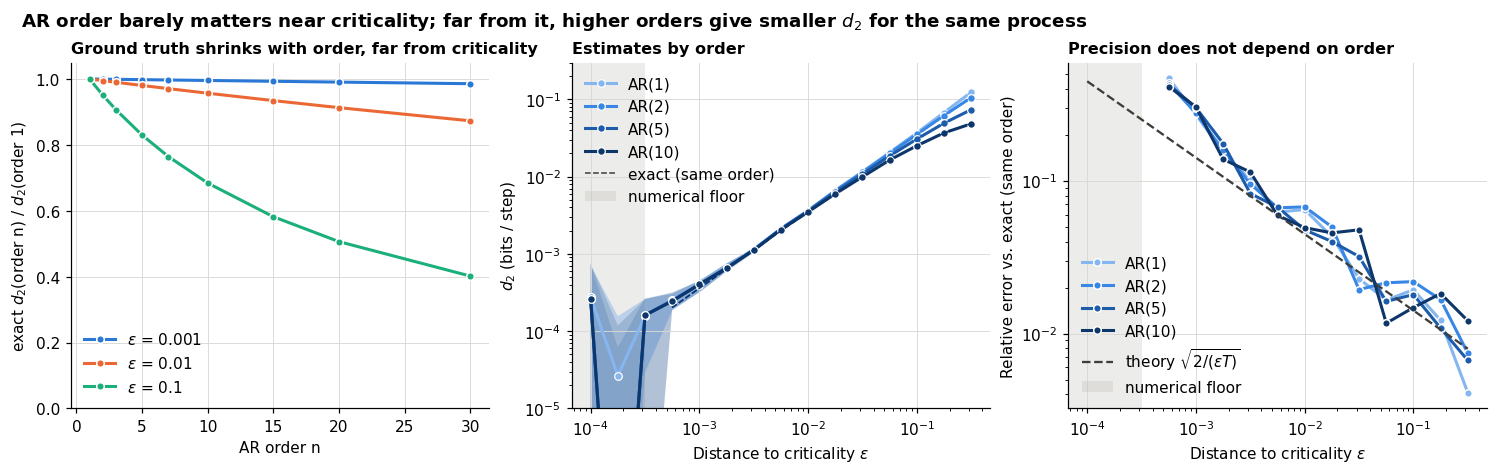

exact d_2 relative to order 1:
order  eps=0.001   eps=0.01    eps=0.1   
    1       1.000       1.000       1.000
    2       1.000       0.995       0.951
    3       0.999       0.990       0.907
    5       0.998       0.980       0.830
    7       0.997       0.971       0.765
   10       0.996       0.957       0.684
   15       0.993       0.934       0.582
   20       0.991       0.913       0.506
   30       0.986       0.873       0.402
AR( 1): above the floor Spearman rho with epsilon = 0.9957, median relative error +0.006, failed fits 0
AR( 2): above the floor Spearman rho with epsilon = 0.9957, median relative error +0.007, failed fits 0
AR( 5): above the floor Spearman rho with epsilon = 0.9957, median relative error +0.007, failed fits 0
AR(10): above the floor Spearman rho with epsilon = 0.9957, median relative error +0.003, failed fits 0


In [10]:
ORDERS_EXACT = (1, 2, 3, 5, 7, 10, 15, 20, 30)
# exact_by_order = ndarray (len(ORDERS_EXACT), len(EXAMPLE_DISTANCES)) of exact d_2 (bits/step). Order 30 takes ~12 s per point.
exact_by_order = np.array(
    [true_db(EXAMPLE_DISTANCES, order=order) for order in ORDERS_EXACT]
)
exact_relative = exact_by_order / exact_by_order[0]  # relative to order 1

fig, (ax_exact, ax_value, ax_error) = plt.subplots(
    1, 3, figsize=(13.5, 4.2), layout="constrained"
)
for distance, relative in zip(EXAMPLE_DISTANCES, exact_relative.T):
    ax_exact.plot(
        ORDERS_EXACT,
        relative,
        color=DISTANCE_COLORS[distance],
        marker="o",
        markersize=5,
        markeredgecolor="white",
        label=rf"$\epsilon$ = {distance:g}",
    )
ax_exact.set(
    xlabel="AR order n",
    ylabel=r"exact $d_2$(order n) / $d_2$(order 1)",
    ylim=(0, 1.05),
    title="Ground truth shrinks with order, far from criticality",
)
ax_exact.legend(loc="lower left")

for order in ORDERS:
    color = ORDER_COLORS[order]
    plot_median_iqr(
        ax_value, DISTANCES, estimates[(order, 2)], color, label=f"AR({order})"
    )
    ax_value.plot(
        DISTANCES[above_floor],
        truths[(order, 2)][above_floor],
        color=color,
        linestyle="--",
        linewidth=1,
    )
    relative_error = (
        estimates[(order, 2)][above_floor] / truths[(order, 2)][above_floor, None] - 1
    )
    ax_error.plot(
        DISTANCES[above_floor],
        1.4826 * np.nanmedian(np.abs(relative_error), axis=1),
        color=color,
        marker="o",
        markersize=5,
        markeredgecolor="white",
        label=f"AR({order})",
    )
ax_value.plot(
    [], [], color=TRUTH_COLOR, linestyle="--", linewidth=1, label="exact (same order)"
)
ax_value.set(
    xscale="log",
    yscale="log",
    ylim=(1e-5, 0.3),
    xlabel=r"Distance to criticality $\epsilon$",
    ylabel=r"$d_2$ (bits / step)",
    title="Estimates by order",
)
ax_error.plot(
    dense_distances,
    np.sqrt(2 / (dense_distances * T_WINDOW)),
    color=TRUTH_COLOR,
    linestyle="--",
    linewidth=1.5,
    label=r"theory $\sqrt{2/(\epsilon T)}$",
)
ax_error.set(
    xscale="log",
    yscale="log",
    xlim=ax_value.get_xlim(),
    xlabel=r"Distance to criticality $\epsilon$",
    ylabel=r"Relative error vs. exact (same order)",
    title="Precision does not depend on order",
)
for ax in (ax_value, ax_error):
    shade_numerical_floor(ax)
ax_value.legend(loc="upper left")
ax_error.legend(loc="lower left")
fig.suptitle(
    r"AR order barely matters near criticality; far from it, higher orders give smaller $d_2$ for the same process",
    fontweight="bold",
    x=0.01,
    ha="left",
)
plt.show()
# fig.savefig(FIGURES_DIR / "sooter_x_bn_ar_order.png", dpi=200, bbox_inches="tight")

print("exact d_2 relative to order 1:")
print("order  " + "  ".join(f"eps={distance:<6g}" for distance in EXAMPLE_DISTANCES))
for order, relative in zip(ORDERS_EXACT, exact_relative):
    print(f"{order:5d}  " + "  ".join(f"{value:10.3f}" for value in relative))
for order in ORDERS:
    rho, _ = spearmanr(
        distances_repeated[above_floor].ravel(),
        estimates[(order, 2)][above_floor].ravel(),
        nan_policy="omit",
    )
    relative_error = (
        estimates[(order, 2)][above_floor] / truths[(order, 2)][above_floor, None] - 1
    )
    print(
        f"AR({order:2d}): above the floor Spearman rho with epsilon = {rho:.4f}, median relative error {np.nanmedian(relative_error):+.3f}, failed fits {np.isnan(estimates[(order, 2)]).sum()}"
    )
# Why the order matters only far from criticality: an AR(n) critical model can copy the true spectrum everywhere except in a band of width ~1/n around omega = 0, where it must have its zero. Near criticality the true spectrum's own peak (width ~epsilon) is much narrower than 1/n, so the extra freedom does not help.

**Take-home.** The AR order is part of the *definition* of $d_2$, not just a fitting detail: the same process has a smaller $d_2$ at higher order, because the critical manifold $M_2^{(n)}$ grows with $n$ and can approximate the true spectrum better. Near criticality this effect is negligible (at $\epsilon = 10^{-3}$, AR(30) is 1.4% below AR(1)); far from criticality it is large (at $\epsilon = 0.1$, AR(10) is 32% and AR(30) 60% below AR(1)). The estimates follow the exact value of their own order, and the ranking by $\epsilon$ is identical for all orders. Higher orders cost no precision here (the true process is AR(1), and the extra coefficients are estimated as ~0), only computation time (~1 s per estimate at order 10 vs. 0.3 s at order 5). **So $d_2$ values can be compared only at the same AR order.** AR(10) instead of AR(5) changes nothing near criticality and compresses the scale far from it.

## 4. Type of criticality $b$

$M_b$ is the set of AR models with a $b/2$-fold root of the characteristic polynomial at $z = 1$. $b = 2$ is the ordinary critical point of a branching process (a single slow mode); $b = 4, 6$ are higher-order critical points (in Sooter's interpretation: also the slow mode's own dynamics are critical). The branching network approaches $M_2$ as $\epsilon \to 0$, but none of the higher manifolds. A correct measure should therefore give $d_2 \to 0$ while $d_4, d_6$ stay finite. AR order 5 throughout.

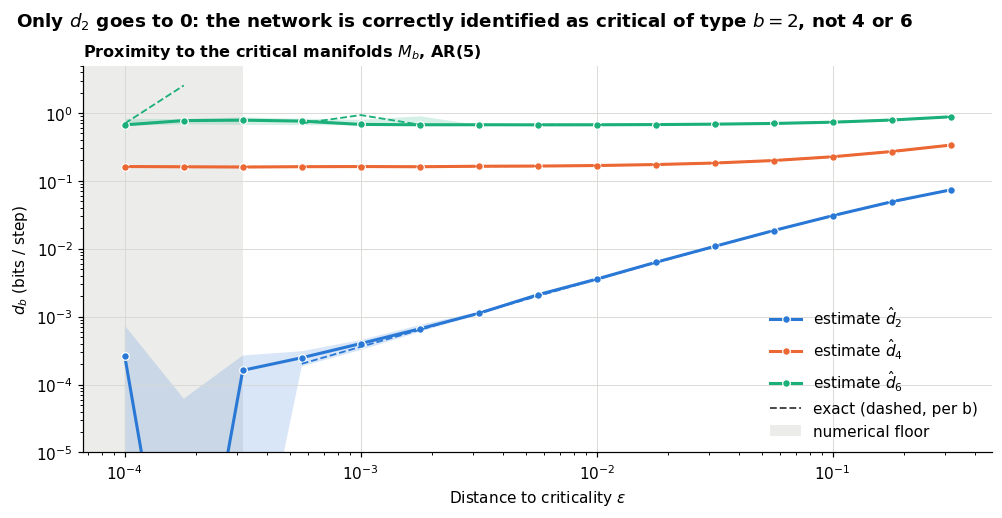

epsilon     d_2 exact / median est.   d_4 exact / median est.   d_6 exact / median est.
 1.0e-04  -7.62e-12 /  2.62e-04    1.61e-01 /  1.63e-01    7.00e-01 /  6.68e-01
 1.8e-04   2.64e-09 /  2.53e-09    1.61e-01 /  1.61e-01    2.54e+00 /  7.72e-01
 3.2e-04   3.05e-08 /  1.62e-04    1.61e-01 /  1.60e-01         nan /  7.83e-01
 5.6e-04   2.03e-04 /  2.48e-04    1.61e-01 /  1.62e-01    7.02e-01 /  7.59e-01
 1.0e-03   3.60e-04 /  4.02e-04    1.62e-01 /  1.63e-01    9.31e-01 /  6.78e-01
 1.8e-03   6.39e-04 /  6.62e-04    1.62e-01 /  1.61e-01    6.72e-01 /  6.70e-01
 3.2e-03   1.13e-03 /  1.12e-03    1.63e-01 /  1.64e-01         nan /  6.71e-01
 5.6e-03   2.01e-03 /  2.10e-03    1.65e-01 /  1.65e-01    6.72e-01 /  6.69e-01
 1.0e-02   3.54e-03 /  3.58e-03    1.68e-01 /  1.68e-01    6.68e-01 /  6.70e-01
 1.8e-02   6.22e-03 /  6.32e-03    1.74e-01 /  1.74e-01    6.74e-01 /  6.75e-01
 3.2e-02   1.08e-02 /  1.09e-02    1.83e-01 /  1.83e-01    6.84e-01 /  6.84e-01
 5.6e-02   1.85e-02 /  1.85e-02 

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.6), layout="constrained")
for b in BETAS:
    color = BETA_COLORS[b]
    plot_median_iqr(
        ax, DISTANCES, estimates[(ORDER, b)], color, label=rf"estimate $\hat d_{b}$"
    )
    # the d_2 floor (section 0) does not matter for b = 4, 6: missing the peak of width ~epsilon at omega = 0 is an O(epsilon) error, negligible against d_4, d_6 >> epsilon
    exact_shown = above_floor if b == 2 else np.ones(len(DISTANCES), dtype=bool)
    ax.plot(
        DISTANCES[exact_shown],
        truths[(ORDER, b)][exact_shown],
        color=color,
        linestyle="--",
        linewidth=1.2,
    )
ax.plot(
    [],
    [],
    color=TRUTH_COLOR,
    linestyle="--",
    linewidth=1.2,
    label="exact (dashed, per b)",
)
ax.set(
    xscale="log",
    yscale="log",
    ylim=(1e-5, 5),
    xlabel=r"Distance to criticality $\epsilon$",
    ylabel=r"$d_b$ (bits / step)",
    title=f"Proximity to the critical manifolds $M_b$, AR({ORDER})",
)
shade_numerical_floor(ax)
ax.legend(loc="lower right")
fig.suptitle(
    r"Only $d_2$ goes to 0: the network is correctly identified as critical of type $b = 2$, not 4 or 6",
    fontweight="bold",
    x=0.01,
    ha="left",
)
plt.show()
# fig.savefig(FIGURES_DIR / "sooter_x_bn_beta.png", dpi=200, bbox_inches="tight")

print("epsilon     " + "   ".join(f"d_{b} exact / median est." for b in BETAS))
for i, distance in enumerate(DISTANCES):
    print(
        f"{distance:8.1e}  "
        + "   ".join(
            f"{truths[(ORDER, b)][i]:9.2e} / {np.nanmedian(estimates[(ORDER, b)][i]):9.2e}"
            for b in BETAS
        )
    )

**Take-home.** $d_4$ and $d_6$ saturate at ~0.16 and ~0.67 bits/step as $\epsilon \to 0$: even the exactly critical branching network is far from the type-4 and type-6 manifolds. So the family $d_b$ classifies the type of criticality correctly, and $d_2$ is the right measure for a branching network. Two numerical caveats for $b = 6$: (i) the "exact" curve has spikes and gaps (nan = "drifted off of critical manifold"), because the optimizer stops above the true minimum (NOTICE.md, known issues; at $\epsilon = 10^{-4}$ SLSQP gives 0.700, multi-start Nelder-Mead 0.661 bits/step); (ii) the estimates are therefore upper bounds, uncertain by ~5%. For $b = 4$ the optimizer is reliable (Nelder-Mead agrees to 4 digits).

## 5. Subsampling: observing only part of the network

In experiments only a fraction $f = n/N$ of the neurons is recorded. In the all-to-all network the active neurons at each step are a uniformly random set (independently across steps, for the non-refractory model), so the count in a fixed observed subset of $n$ neurons is $X_t \sim \mathrm{Hypergeometric}(N, A_t, n)$, drawn independently for each step. No raster is needed.

**Theory.** $X_t = f A_t + \eta_t$ with white sampling noise $\eta_t$ (uncorrelated with the past): an ARMA(1,1) process, not AR(1) anymore. The autocovariance at lags $k \geq 1$ is $f^2 \mathrm{Cov}(A_t, A_{t+k})$, but the variance gains $E[\mathrm{Var}(X_t \mid A_t)]$. Inserting the hypergeometric variance and the stationary $\mathrm{Var}(A)$ (`stationary_var_aa`), all finite-$N$ terms cancel and the autocorrelation is reduced by exactly
$$c = \frac{f}{f + (1-f)(1-\phi^2)} \approx \frac{f}{f + 2\epsilon(1-f)}, \qquad \phi = 1 - \epsilon.$$
An AR(1) fit then sees $\hat\phi = c\,\phi$, i.e. the apparent distance $\epsilon_\mathrm{app} = 1 - c\phi \approx \epsilon\,(1 + 2(1-f)/f)$. For $\epsilon \ll 1$ the bias depends only on $f$, not on $N$, the rate, or $\epsilon$: **observing 10% of the network makes it look 19 times further from criticality.**

In [12]:
FRACTIONS = np.array(
    [1, 0.5, 0.2, 0.1, 0.05, 0.02]
)  # observed fraction of neurons f = n / N
rng = np.random.default_rng(seed=5)
# subsampled_db[(order, epsilon)] = ndarray (len(FRACTIONS), N_REPEATS)
subsampled_db = {}
for i, distance in enumerate(EXAMPLE_DISTANCES):
    activity = simulate(distance, seed=(5, i))
    for order in (1, ORDER):
        subsampled_db[(order, distance)] = np.empty((len(FRACTIONS), N_REPEATS))
    for j, fraction in enumerate(FRACTIONS):
        n_observed = int(round(fraction * N_NEURONS))
        # observed = ndarray (N_REPEATS, T) of int: active neurons among the n observed
        observed = rng.hypergeometric(
            ngood=activity, nbad=N_NEURONS - activity, nsample=n_observed
        )
        for order in (1, ORDER):
            subsampled_db[(order, distance)][j] = estimate_db(observed, order=order)

subsampled_truth = {
    order: dict(zip(EXAMPLE_DISTANCES, true_db(EXAMPLE_DISTANCES, order=order)))
    for order in (1, ORDER)
}
print(
    f"observed neurons n: {np.round(FRACTIONS * N_NEURONS).astype(int)} of N = {N_NEURONS}; mean observed count at the smallest n: {RATE * FRACTIONS[-1] * N_NEURONS:.1f} spikes/step"
)
for (order, distance), db in subsampled_db.items():
    print(
        f"AR({order}), epsilon = {distance:g}: shape {db.shape}, median d_2 / exact: {np.round(np.nanmedian(db, axis=1) / subsampled_truth[order][distance], 2)}"
    )

observed neurons n: [1000  500  200  100   50   20] of N = 1000; mean observed count at the smallest n: 2.0 spikes/step
AR(1), epsilon = 0.001: shape (6, 10), median d_2 / exact: [ 1.03  3.09  9.17 19.61 38.97 95.56]
AR(5), epsilon = 0.001: shape (6, 10), median d_2 / exact: [1.03 1.06 1.34 1.96 3.28 7.35]
AR(1), epsilon = 0.01: shape (6, 10), median d_2 / exact: [ 1.03  3.04  8.62 17.18 30.88 58.13]
AR(5), epsilon = 0.01: shape (6, 10), median d_2 / exact: [1.04 1.06 1.37 1.97 3.18 6.43]
AR(1), epsilon = 0.1: shape (6, 10), median d_2 / exact: [ 1.01  2.55  5.48  7.96 10.05 11.89]
AR(5), epsilon = 0.1: shape (6, 10), median d_2 / exact: [1.01 1.08 1.35 1.76 2.34 3.14]


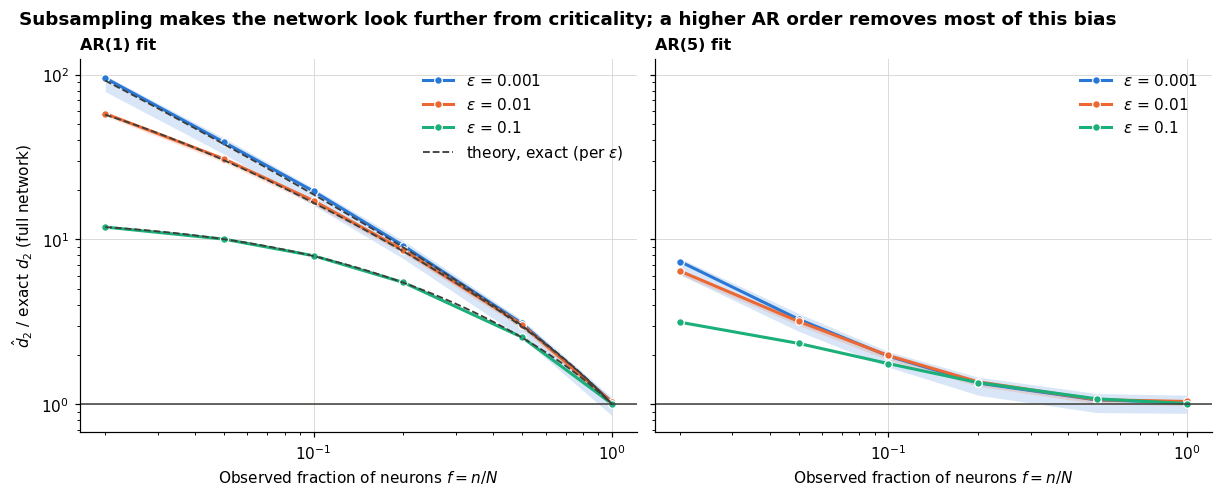

In [13]:
dense_fractions = np.logspace(np.log10(FRACTIONS[-1]), 0, 100)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), layout="constrained", sharey=True)
for ax, order in zip(axes, (1, ORDER)):
    for distance in EXAMPLE_DISTANCES:
        ratio = subsampled_db[(order, distance)] / subsampled_truth[order][distance]
        plot_median_iqr(
            ax,
            FRACTIONS,
            ratio,
            DISTANCE_COLORS[distance],
            label=rf"$\epsilon$ = {distance:g}",
        )
    ax.axhline(1, color=TRUTH_COLOR, linewidth=1)
    ax.set(
        xscale="log",
        yscale="log",
        xlabel=r"Observed fraction of neurons $f = n / N$",
        title=f"AR({order}) fit",
    )
# AR(1) theory: apparent kernel c * phi, then the order-1 closed form of d_2
for distance in EXAMPLE_DISTANCES:
    phi = 1 - distance
    attenuation = dense_fractions / (
        dense_fractions + (1 - dense_fractions) * (1 - phi**2)
    )  # c
    apparent_distance = 1 - attenuation * phi
    theory_ratio = np.log2(1 - apparent_distance / 2) / np.log2(1 - distance / 2)
    axes[0].plot(
        dense_fractions, theory_ratio, color=TRUTH_COLOR, linestyle="--", linewidth=1.2
    )
axes[0].plot(
    [],
    [],
    color=TRUTH_COLOR,
    linestyle="--",
    linewidth=1.2,
    label=r"theory, exact (per $\epsilon$)",
)
for ax in axes:
    ax.legend(loc="upper right")
axes[0].set_ylabel(r"$\hat d_2$ / exact $d_2$ (full network)")
fig.suptitle(
    r"Subsampling makes the network look further from criticality; a higher AR order removes most of this bias",
    fontweight="bold",
    x=0.01,
    ha="left",
)
plt.show()
# fig.savefig(FIGURES_DIR / "sooter_x_bn_subsampling.png", dpi=200, bbox_inches="tight")

**Take-home.** Subsampling biases $d_2$ **upwards**, i.e. away from criticality, and the AR(1) fits follow the theory exactly. With AR(1), observing 10% of the neurons inflates $d_2$ ~19-fold near criticality. AR(5) absorbs most of the sampling noise, because the ARMA(1,1) process is approximated better by a longer AR kernel; the bias at 10% observation drops to ~2-fold, and near criticality it is again nearly independent of $\epsilon$. Consequences for data: (i) absolute $d_2$ values from recordings of a small fraction of a network overestimate the distance; (ii) comparisons (e.g. WAKE vs. NREM) remain valid if the same neurons are recorded, because the bias factor depends on $f$ but hardly on $\epsilon$; (iii) here higher AR orders help, unlike for the fully observed network (section 3).

## 6. Network size and firing rate

By the ground-truth argument above, neither $N$ nor the rate changes the second-order statistics, so $d_2$ should not depend on them. What can change is the precision: at small $N \cdot$ rate the counts are small integers (non-Gaussian, heteroscedastic noise), while the fit assumes Gaussian noise. Distance $\epsilon = 10^{-2}$, full network observed, order 5.

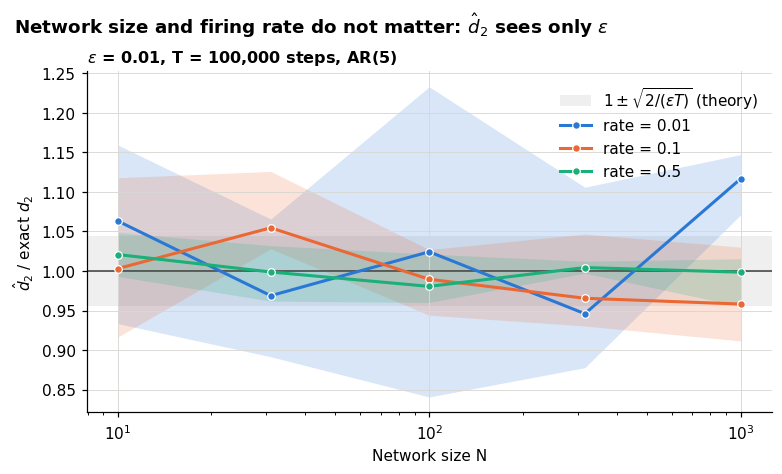

exact d_2 = 3.545e-03 bits/step
rate 0.01: mean active neurons per step [ 0.1  0.3  1.   3.2 10. ]; median ratio [1.063 0.969 1.024 0.946 1.117]; failed 0
rate 0.1: mean active neurons per step [  1.    3.1  10.   31.6 100. ]; median ratio [1.003 1.055 0.99  0.966 0.958]; failed 0
rate 0.5: mean active neurons per step [  5.   15.5  50.  158.  500. ]; median ratio [1.021 0.999 0.981 1.004 0.998]; failed 0


In [14]:
SIZES = np.unique(np.logspace(1, np.log10(N_NEURONS), 5).astype(int))
SIZE_DISTANCE = 1e-2
size_truth = true_db([SIZE_DISTANCE])[0]
# size_db[rate] = ndarray (len(SIZES), N_REPEATS)
size_db = {
    rate: np.array(
        [
            estimate_db(simulate(SIZE_DISTANCE, N=size, rate=rate, seed=(6, i, j)))
            for j, size in enumerate(SIZES)
        ]
    )
    for i, rate in enumerate(RATE_COLORS)
}

fig, ax = plt.subplots(figsize=(7, 4.2), layout="constrained")
relative_std_theory = np.sqrt(2 / (SIZE_DISTANCE * T_WINDOW))
ax.axhspan(
    1 - relative_std_theory,
    1 + relative_std_theory,
    color=TRUTH_COLOR,
    alpha=0.08,
    linewidth=0,
    label=r"$1 \pm \sqrt{2/(\epsilon T)}$ (theory)",
)
ax.axhline(1, color=TRUTH_COLOR, linewidth=1)
for rate, db in size_db.items():
    plot_median_iqr(
        ax, SIZES, db / size_truth, RATE_COLORS[rate], label=f"rate = {rate}"
    )
ax.set(
    xscale="log",
    xlabel="Network size N",
    ylabel=r"$\hat d_2$ / exact $d_2$",
    title=rf"$\epsilon$ = {SIZE_DISTANCE:g}, T = {T_WINDOW:,} steps, AR({ORDER})",
)
ax.legend(loc="upper right")
fig.suptitle(
    r"Network size and firing rate do not matter: $\hat d_2$ sees only $\epsilon$",
    fontweight="bold",
    x=0.01,
    ha="left",
)
plt.show()
# fig.savefig(FIGURES_DIR / "sooter_x_bn_size_rate.png", dpi=200, bbox_inches="tight")

print(f"exact d_2 = {size_truth:.3e} bits/step")
for rate, db in size_db.items():
    print(
        f"rate {rate}: mean active neurons per step {np.round(rate * SIZES, 1)}; median ratio {np.round(np.nanmedian(db, axis=1) / size_truth, 3)}; failed {np.isnan(db).sum()}"
    )

**Take-home.** As predicted, the estimate is unbiased for every combination of $N$ and rate, down to 10 neurons with on average 0.1 active neurons per step, although the counts are then mostly 0 and far from Gaussian. The spread is somewhat larger for the sparsest networks (rate 0.01), but stays of the order of the theory band.

## Summary

| question | answer (all-to-all BN, `delta_t` = 1 step) |
|---|---|
| Does $\hat d_2$ correlate with the true distance? | Yes: monotonic and proportional to $\epsilon$; $d_2 \approx \epsilon/(4\ln 2) \approx 1/(4 \ln 2\,\tau)$ bits/step near criticality. |
| Numerical limits? | `calc_db` returns $d_2 \approx 0$ for $\tau \gtrsim$ 3000 steps ($\epsilon \lesssim 3 \cdot 10^{-4}$): the quadrature misses the narrow low-frequency peak. Such systems look exactly critical. |
| Window length? | Relative error $\approx \sqrt{2\tau/T}$; 10% needs $T \approx 200\,\tau$. Short windows ($T \lesssim 10\,\tau$) bias $d_2$ upwards. Error bars are trustworthy only for $T \gtrsim 50\,\tau$. |
| AR order (e.g. AR(10))? | Part of the definition of $d_2$: higher order gives smaller $d_2$ far from criticality (AR(10) vs AR(1): -32% at $\epsilon = 0.1$), negligible near criticality. Same ranking, same precision, more compute. Compare values only at equal order. |
| $b = 2, 4, 6$? | Only $d_2 \to 0$; $d_4 \approx 0.16$, $d_6 \approx 0.67$ bits/step stay finite: correct type of criticality. $b = 6$ suffers from optimizer issues (~5%). |
| Subsampling? | Inflates $d_2$ by $\approx 1 + 2(1-f)/f$ with AR(1) (×19 at $f$ = 10%), ~×2 with AR(5). Comparisons at equal $f$ stay valid. |
| $N$, rate? | No effect. |

Numbers are from the drafting run (`N_NEURONS` = 1000, `T_WINDOW` = $10^5$, `N_REPEATS` = 10); rerun at a larger scale to tighten the error-bar coverage and the window-length curves.

In [15]:
POOL.shutdown()